# 04 — Feature Engineering: Historical Crop Yield
**Crop Yield Prediction and Forecasting Using Machine Learning**

This notebook **adds** historical yield features to our existing records. It does not replace the preprocessing notebook or implement feature selection. The code is deliberately short and readable, like the EDA notebook.

**Research question:** Can past yield of the *same crop in the same district* improve one-year-ahead estimates, and how often is that history available?

**Prediction definition:** A *rolling one-year-ahead* estimate for year `t` can use yield observed in calendar years `t−1`, `t−2` and `t−3`, assuming those statistics are published by the prediction date. It cannot use yield for `t` or later. This is **not** a fixed-origin 2015–2017 forecast, and availability/publication delays must be checked for deployment.

We will evaluate a simple historical-average baseline on **2012–2014 validation** only. No feature-selection algorithms, full ML models, hyperparameter tuning, or final-test metrics are run here.

## 1. Imports and project paths

Run this notebook from the repository root or the `notebooks/` folder. It loads the same raw CSV as the existing EDA/preprocessing notebooks.

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "crop_yield_dataset.csv"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "feature_engineering"
assert RAW_PATH.is_file(), f"Dataset not found: {RAW_PATH}"

df = pd.read_csv(RAW_PATH)
print("Rows and columns:", df.shape)
display(df.head(3))

Rows and columns: (198369, 15)


,Year,Region,Crop,Season,Temperature,Rainfall,Humidity,Soil Type,pH,Nitrogen,Phosphorus,Potassium,Fertilizer,Pesticide,Yield
0,1966,"Anantapur, AndhraPradesh",Castor,Kharif,25.85,623.8,59.9,Alfisols,6.2,2.8,0.28,0.0,3.07,0.44,192.66
1,1966,"Anantapur, AndhraPradesh",Chickpea,Rabi,25.85,623.8,59.9,Alfisols,6.2,2.8,0.28,0.0,3.07,0.44,500.00
2,1966,"Anantapur, AndhraPradesh",Cotton,Kharif,25.85,623.8,59.9,Alfisols,6.2,2.8,0.28,0.0,3.07,0.44,47.62


## 2. Confirm the historical record key and chronological split

`Year + Region + Crop` identifies an observed yield for an individual crop, district and year. The original `Season` column is tied to the crop in this dataset; retain it as a regular input but do not use it to disguise duplicate records.

The boundaries match the existing project: train ≤2011, validation 2012–2014, test 2015–2017. The final test period is kept for later model evaluation.

In [3]:
KEY = ["Region", "Crop", "Year"]
needed = KEY + ["Yield", "Temperature", "Rainfall", "Humidity", "Soil Type", "pH",
                "Nitrogen", "Phosphorus", "Potassium", "Season"]
assert set(needed).issubset(df.columns), "Required input columns are missing"
assert not df.duplicated(KEY).any(), "Duplicate region-crop-year records need investigation"
assert df["Year"].between(1966, 2017).all()

train_mask = df["Year"] <= 2011
val_mask = df["Year"].between(2012, 2014)
test_mask = df["Year"].between(2015, 2017)
assert (train_mask.astype(int) + val_mask.astype(int) + test_mask.astype(int)).eq(1).all()
print("Train / Validation / Test:", train_mask.sum(), val_mask.sum(), test_mask.sum())

Train / Validation / Test: 176196 11345 10828


## 3. Create exact-calendar-year lag features

A pandas `groupby().shift()` alone can accidentally treat 2010 as the previous **year** of 2012 when 2011 is missing. Here we join explicitly on exact years, so missing years become `NaN` rather than being silently skipped.

**Important:** This function uses the observed yield of earlier years as inputs. It does not use the current row's `Yield` to create that row's lag values.

In [12]:

def add_historical_features(data):
    result = data.copy()
    history = data[["Region", "Crop", "Year", "Yield"]].copy()

    # Exact-calendar-year yield lags
    for lag in (1, 2, 3, 5):
        previous = history.rename(columns={
            "Year": "History_Year",
            "Yield": f"Yield_Lag{lag}"
        })

        result["History_Year"] = result["Year"] - lag
        result = result.merge(
            previous,
            on=["Region", "Crop", "History_Year"],
            how="left",
            validate="many_to_one",
            sort=False
        ).drop(columns="History_Year")

    # Statistics from the previous three calendar years
    lag_cols = ["Yield_Lag1", "Yield_Lag2", "Yield_Lag3"]

    result["Yield_Rolling3"] = result[lag_cols].mean(
        axis=1, skipna=False
    )
    result["Yield_Rolling3_Std"] = result[lag_cols].std(
        axis=1, ddof=0, skipna=False
    )

    # Change from five years ago to the previous year
    result["Yield_Trend5"] = (
        result["Yield_Lag1"] - result["Yield_Lag5"]
    )

    # Historical availability indicators
    result["History_Lag1_Available"] = (
        result["Yield_Lag1"].notna().astype(int)
    )
    result["History_3yr_Complete"] = (
        result[lag_cols].notna().all(axis=1).astype(int)
    )

    # Climate averages using previous observations only
    climate = data[
        ["Region", "Crop", "Year", "Temperature", "Rainfall"]
    ].sort_values(["Region", "Crop", "Year"]).copy()

    groups = climate.groupby(["Region", "Crop"])

    for col in ["Temperature", "Rainfall"]:
        climate[f"{col}_History_Mean"] = groups[col].transform(
            lambda s: s.shift(1).expanding(min_periods=3).mean()
        )

    climate["Temperature_Anomaly"] = (
        climate["Temperature"] -
        climate["Temperature_History_Mean"]
    )
    climate["Rainfall_Anomaly"] = (
        climate["Rainfall"] -
        climate["Rainfall_History_Mean"]
    )

    result = result.merge(
        climate[
            ["Region", "Crop", "Year",
             "Temperature_Anomaly", "Rainfall_Anomaly"]
        ],
        on=["Region", "Crop", "Year"],
        how="left",
        validate="one_to_one",
        sort=False
    )

    return result


data_fe = add_historical_features(df)

assert len(data_fe) == len(df)
assert data_fe[KEY].equals(df[KEY])

display(data_fe[
    ["Year", "Region", "Crop", "Yield",
     "Yield_Lag1", "Yield_Rolling3",
     "Yield_Rolling3_Std", "Yield_Trend5",
     "Temperature_Anomaly", "Rainfall_Anomaly"]
].tail(50))


,Year,Region,Crop,Yield,Yield_Lag1,Yield_Rolling3,Yield_Rolling3_Std,Yield_Trend5,Temperature_Anomaly,Rainfall_Anomaly
198319,2014,"West Dinajpur, West Bengal",Barley,1500.00,1500.00,1833.333333,235.702260,NaN,-0.430811,-361.321622
198320,2014,"West Dinajpur, West Bengal",Chickpea,1000.00,NaN,NaN,NaN,NaN,-0.408718,-339.702564
198321,2014,"West Dinajpur, West Bengal",Finger Millet,842.11,842.11,871.116667,20.683857,NaN,-0.031250,-259.881250
198322,2014,"West Dinajpur, West Bengal",Groundnut,2400.00,2400.00,2675.000000,247.487373,786.36,0.143750,-328.243750
198323,2014,"West Dinajpur, West Bengal",Linseed,462.18,463.92,466.753333,2.813922,266.64,0.143750,-328.243750
198324,2014,"West Dinajpur, West Bengal",Maize,5526.45,5477.10,5412.750000,159.309096,-531.79,-0.388750,-332.015000
198325,2014,"West Dinajpur, West Bengal",Minor Pulses,774.86,741.38,667.606667,96.334607,-45.47,-0.388750,-332.015000
198326,2014,"West Dinajpur, West Bengal",Rapeseed & Mustard,968.08,876.18,888.430000,60.856649,-32.03,-0.388750,-332.015000
198327,2014,"West Dinajpur, West Bengal",Rice,2804.31,2623.38,2641.316667,13.722129,334.21,-0.388750,-332.015000
198328,2014,"West Dinajpur, West Bengal",Sesamum,633.80,640.21,584.433333,46.994003,145.26,-0.023333,-213.772222


## 4. Verify exact-year correspondence and leakage safety

Check each lag against a direct merge of prior-year yields. The 3-year mean is available only when all three immediately preceding years exist. We will **not** fill missing lags with the current yield or with future observations.

In [5]:

# Verify the exact previous-year yield
previous_year = df[KEY + ["Yield"]].copy()
previous_year["Year"] += 1
previous_year = previous_year.rename(
    columns={"Yield": "Expected_Lag1"}
)

check = data_fe[KEY + ["Yield_Lag1"]].merge(
    previous_year, on=KEY,
    how="left", validate="one_to_one"
)

assert np.allclose(
    check["Yield_Lag1"],
    check["Expected_Lag1"],
    equal_nan=True
)

# Verify the five-year lag
five_years = df[KEY + ["Yield"]].copy()
five_years["Year"] += 5
five_years = five_years.rename(
    columns={"Yield": "Expected_Lag5"}
)

check5 = data_fe[KEY + ["Yield_Lag5"]].merge(
    five_years, on=KEY,
    how="left", validate="one_to_one"
)

assert np.allclose(
    check5["Yield_Lag5"],
    check5["Expected_Lag5"],
    equal_nan=True
)

# Verify missing-history behavior
assert data_fe.loc[
    data_fe["Year"] == 1966, "Yield_Lag1"
].isna().all()

assert data_fe.loc[
    data_fe["History_3yr_Complete"] == 0,
    "Yield_Rolling3"
].isna().all()

assert data_fe.loc[
    data_fe["History_3yr_Complete"] == 0,
    "Yield_Rolling3_Std"
].isna().all()

# Verify historical climate anomalies
first_year = data_fe.groupby(
    ["Region", "Crop"]
)["Year"].transform("min")

assert data_fe.loc[
    data_fe["Year"] == first_year,
    ["Temperature_Anomaly", "Rainfall_Anomaly"]
].isna().all().all()

print("Historical feature checks passed.")
print("All rows retained:", len(data_fe) == len(df))

print("\nFeature availability:")
display(data_fe[
    ["Yield_Lag1", "Yield_Rolling3",
     "Yield_Rolling3_Std", "Yield_Trend5",
     "Temperature_Anomaly", "Rainfall_Anomaly"]
].notna().sum().to_frame("Available Records"))


Historical feature checks passed.
All rows retained: True

Feature availability:


,Available Records
Yield_Lag1,185685
Yield_Rolling3,168207
Yield_Rolling3_Std,168207
Yield_Trend5,162149
Temperature_Anomaly,182949
Rainfall_Anomaly,182949


## 5. Availability and gaps

Missing historical yields are expected for early years and for crop–district combinations with observation gaps. These are **not** ordinary missing weather values and should not be silently replaced in preprocessing. We track coverage separately for each partition and crop.

In [6]:
data_fe["Partition"] = np.select(
    [data_fe["Year"] <= 2011, data_fe["Year"].between(2012, 2014)],
    ["Train", "Validation"], default="Test"
)
coverage = data_fe.groupby("Partition").agg(
    records=("Yield", "size"),
    lag1_available=("History_Lag1_Available", "sum"),
    full_3yr_history=("History_3yr_Complete", "sum")
)
coverage["lag1_pct"] = (100 * coverage["lag1_available"] / coverage["records"]).round(2)
coverage["rolling3_pct"] = (100 * coverage["full_3yr_history"] / coverage["records"]).round(2)
display(coverage)

crop_coverage = data_fe.groupby(["Partition", "Crop"])["History_3yr_Complete"].agg(["sum", "count"])
crop_coverage["coverage_pct"] = 100 * crop_coverage["sum"] / crop_coverage["count"]
display(crop_coverage.loc["Validation"].sort_values("coverage_pct").head(8).round(1))

,records,lag1_available,full_3yr_history,lag1_pct,rolling3_pct
Partition,,,,,
Test,10828,10160,9123,93.83,84.25
Train,176196,164915,149118,93.60,84.63
Validation,11345,10610,9966,93.52,87.84


,sum,count,coverage_pct
Crop,,,
Minor Pulses,515,742,69.4
Castor,238,319,74.6
Sorghum (Rabi),157,207,75.8
Safflower,104,137,75.9
Sorghum (Kharif),433,547,79.2
Sunflower,304,370,82.2
Soybean,315,379,83.1
Pearl Millet,445,529,84.1


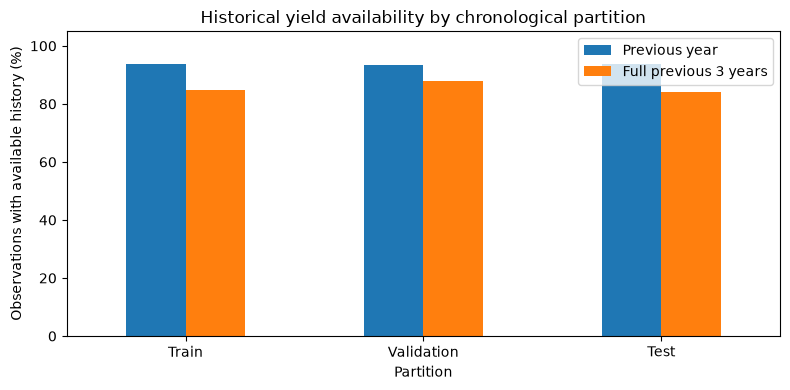

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_data = coverage.reindex(["Train", "Validation", "Test"])[["lag1_pct", "rolling3_pct"]]
plot_data.plot(kind="bar", ax=ax)
ax.set_title("Historical yield availability by chronological partition")
ax.set_xlabel("Partition")
ax.set_ylabel("Observations with available history (%)")
ax.set_ylim(0, 105)
ax.legend(["Previous year", "Full previous 3 years"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretation:** Compare coverage before comparing model scores. Results reported only on complete-history rows can appear better simply because they evaluate an easier subset.

## 6. Validate a simple historical baseline on 2012–2014 only

The first baseline predicts yield using the preceding year's value (`Lag1`); the second uses the mean of the three **exact prior calendar years**. These are not trained ML models.

Evaluate both on the **same complete-history validation cohort**. Report MAE, RMSE, WAPE and MAPE, with MAPE evaluated only for actual yields ≥10 kg/ha. Do not use the 2015–2017 final holdout to choose methods here.

In [8]:
val_fe = data_fe[data_fe["Year"].between(2012, 2014)].copy()
valid = val_fe[val_fe["History_3yr_Complete"].eq(1)].copy()

if valid.empty:
    print("No validation records have complete three-year history.")
else:
    actual = valid["Yield"].to_numpy(dtype=float)
    rows = []
    for label, col in [("Previous-year yield", "Yield_Lag1"), ("Previous-3-year mean", "Yield_Rolling3")]:
        pred = valid[col].to_numpy(dtype=float)
        error = actual - pred
        mape_ok = actual >= 10
        rows.append({
            "Baseline": label,
            "Rows": len(valid),
            "MAE (kg/ha)": np.mean(np.abs(error)),
            "RMSE (kg/ha)": np.sqrt(np.mean(error ** 2)),
            "WAPE (%)": 100 * np.sum(np.abs(error)) / np.sum(np.abs(actual)),
            "MAPE >=10 (%)": 100 * np.mean(np.abs(error[mape_ok] / actual[mape_ok])) if mape_ok.any() else np.nan,
            "MAPE eligible rows": int(mape_ok.sum()),
        })
    baseline_results = pd.DataFrame(rows)
    display(baseline_results.round(2))
    print(f"Validation coverage: {len(valid):,} / {len(val_fe):,} ({100*len(valid)/len(val_fe):.1f}%)")

,Baseline,Rows,MAE (kg/ha),RMSE (kg/ha),WAPE (%),MAPE >=10 (%),MAPE eligible rows
0,Previous-year yield,9966,328.35,593.71,19.84,29.90,9966
1,Previous-3-year mean,9966,314.66,562.34,19.02,29.39,9966


Validation coverage: 9,966 / 11,345 (87.8%)


## 7. Outlier history diagnostic

The existing data audit flagged exceptionally large Chickpea yields. **Do not automatically remove or cap them here.** A suspicious training target can also enter future lag features. This cell identifies that risk without modifying the observations.

In [9]:

# Flag previously identified extreme Chickpea records
suspected = data_fe[
    (data_fe["Crop"] == "Chickpea") &
    (data_fe["Year"] <= 2011) &
    (data_fe["Yield"] > 5000)
].copy()

print("Suspected Chickpea observations:", len(suspected))
display(suspected[["Year", "Region", "Crop", "Yield"]])

# Find later rows that could use these yields as history
suspected_keys = suspected[
    ["Region", "Crop", "Year"]
].rename(columns={"Year": "Source_Year"})

affected = data_fe.merge(
    suspected_keys,
    on=["Region", "Crop"],
    how="inner"
)

affected["Years_After_Source"] = (
    affected["Year"] - affected["Source_Year"]
)

affected = affected[
    affected["Years_After_Source"].isin([1, 2, 3, 5])
].copy()

print("\nPotentially affected historical features:")
display(affected[
    ["Year", "Region", "Crop", "Source_Year",
     "Years_After_Source", "Yield_Lag1",
     "Yield_Rolling3", "Yield_Trend5"]
].sort_values(["Region", "Year"]))


Suspected Chickpea observations: 2


,Year,Region,Crop,Yield
15772,2007,"Muzaffarpur, Bihar",Chickpea,58363.64
17654,2007,"Saharsa, Bihar",Chickpea,32000.00



Potentially affected historical features:


,Year,Region,Crop,Source_Year,Years_After_Source,Yield_Lag1,Yield_Rolling3,Yield_Trend5
38,2008,"Muzaffarpur, Bihar",Chickpea,2007,1,58363.64,20046.666667,57363.64
39,2009,"Muzaffarpur, Bihar",Chickpea,2007,2,1090.91,20099.696667,250.91
40,2010,"Muzaffarpur, Bihar",Chickpea,2007,3,1000.00,20151.516667,68.18
42,2012,"Muzaffarpur, Bihar",Chickpea,2007,5,1250.00,1083.333333,-57113.64


## 8. Feature configurations to compare **later**

The original weather, soil and nutrient variables are preserved. Here we **define** three candidate input groups, but we do **not** fit ML models or perform feature selection. Keep comparisons fair by evaluating configurations on identical rows, or reporting the coverage trade-off separately.

The historical-only feature set can support a low-input model if recent published crop yields are actually accessible. The hybrid model adds weather and management assumptions, which need prediction-time availability checks.

In [10]:

# Original identifiers and time feature
CORE = ["Region", "Crop", "Year"]

# Historical yield features
HISTORY = [
    "Yield_Lag1",
    "Yield_Rolling3",
    "Yield_Rolling3_Std",
    "Yield_Trend5",
    "History_Lag1_Available",
    "History_3yr_Complete"
]

# Original agricultural predictors
AGRICULTURAL = [
    "Temperature", "Rainfall", "Humidity",
    "Soil Type", "pH",
    "Nitrogen", "Phosphorus", "Potassium"
]

# Climate anomaly features
CLIMATE_ANOMALIES = [
    "Temperature_Anomaly",
    "Rainfall_Anomaly"
]

# Candidate feature configurations
feature_sets = {
    "E0_basic": CORE,
    "E1_history": CORE + HISTORY,
    "E2_history_agriculture": CORE + HISTORY + AGRICULTURAL,
    "E3_history_climate": (
        CORE + HISTORY + AGRICULTURAL + CLIMATE_ANOMALIES
    )
}

for name, cols in feature_sets.items():
    assert set(cols).issubset(data_fe.columns)
    print(f"{name}: {len(cols)} features")
    print(cols)
    print()


E0_basic: 3 features
['Region', 'Crop', 'Year']

E1_history: 9 features
['Region', 'Crop', 'Year', 'Yield_Lag1', 'Yield_Rolling3', 'Yield_Rolling3_Std', 'Yield_Trend5', 'History_Lag1_Available', 'History_3yr_Complete']

E2_history_agriculture: 17 features
['Region', 'Crop', 'Year', 'Yield_Lag1', 'Yield_Rolling3', 'Yield_Rolling3_Std', 'Yield_Trend5', 'History_Lag1_Available', 'History_3yr_Complete', 'Temperature', 'Rainfall', 'Humidity', 'Soil Type', 'pH', 'Nitrogen', 'Phosphorus', 'Potassium']

E3_history_climate: 19 features
['Region', 'Crop', 'Year', 'Yield_Lag1', 'Yield_Rolling3', 'Yield_Rolling3_Std', 'Yield_Trend5', 'History_Lag1_Available', 'History_3yr_Complete', 'Temperature', 'Rainfall', 'Humidity', 'Soil Type', 'pH', 'Nitrogen', 'Phosphorus', 'Potassium', 'Temperature_Anomaly', 'Rainfall_Anomaly']



## 9. Export for later notebooks — preserve the existing preprocessing outputs

Write separate files under `data/processed/feature_engineering/`. **Never overwrite** `train.csv`, `val.csv` or `test.csv` from your existing preprocessing notebook.

For integration, **if those three files already exist**, merge just the engineered historical columns into each existing partition by the unique `Year + Region + Crop` key. This preserves your existing approved training-only cleaning decisions (including its training-row count) and any other existing columns. Otherwise, create new chronological partitions from the raw source.

Historical lags are calculated from the underlying **raw published history**, not from an in-sample model prediction. Suspected anomalous source values are only flagged here; their propagation into later-year lags must be reviewed as part of the eventual outlier policy.

In [11]:

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# All engineered features to export
history_cols = [
    "Yield_Lag1",
    "Yield_Lag2",
    "Yield_Lag3",
    "Yield_Lag5",
    "Yield_Rolling3",
    "Yield_Rolling3_Std",
    "Yield_Trend5",
    "History_Lag1_Available",
    "History_3yr_Complete",
    "Temperature_Anomaly",
    "Rainfall_Anomaly"
]

lag_table = data_fe[KEY + history_cols].copy()

# Keep the existing chronological boundaries
raw_partitions = {
    "train": data_fe[data_fe["Year"] <= 2011].drop(
        columns="Partition"
    ),
    "val": data_fe[data_fe["Year"].between(2012, 2014)].drop(
        columns="Partition"
    ),
    "test": data_fe[data_fe["Year"] >= 2015].drop(
        columns="Partition"
    )
}

partitions = {}

for name, from_raw in raw_partitions.items():
    existing_path = (
        PROJECT_ROOT / "data" / "processed" / f"{name}.csv"
    )

    if existing_path.is_file():
        existing = pd.read_csv(existing_path)

        assert set(KEY).issubset(existing.columns)
        assert not existing.duplicated(KEY).any()
        assert not any(
            col in existing.columns for col in history_cols
        )

        part = existing.merge(
            lag_table,
            on=KEY,
            how="left",
            validate="one_to_one",
            sort=False
        )

        assert len(part) == len(existing)
        assert part[KEY].equals(existing[KEY])

        print(f"Preserved existing {name} partition")

    else:
        part = from_raw
        print(f"Using chronological {name} partition")

    partitions[name] = part

    output = OUTPUT_DIR / f"{name}_historical_features.csv"
    part.to_csv(output, index=False)

    print(f"Saved: {output.name} ({len(part):,} rows)")

# Save candidate feature configurations
with (OUTPUT_DIR / "feature_sets.json").open(
    "w", encoding="utf-8"
) as f:
    json.dump(feature_sets, f, indent=2)

print("\nFeature engineering exports completed.")


Preserved existing train partition
Saved: train_historical_features.csv (176,194 rows)
Preserved existing val partition
Saved: val_historical_features.csv (11,345 rows)
Preserved existing test partition
Saved: test_historical_features.csv (10,828 rows)

Feature engineering exports completed.


## 10. Integration guide and next steps

**How this fits the existing GitHub project:**

1. Keep the current EDA and preprocessing notebooks. Place this notebook alongside them in `notebooks/`.
2. Run the notebook from the project repository, where `data/raw/crop_yield_dataset.csv` is present.
3. It writes **new** feature-enriched train/validation/test CSVs under `data/processed/feature_engineering/`; it does not overwrite existing processed CSVs.
4. In the *future* feature-selection or model-training notebook, load the relevant `*_historical_features.csv`, use a chosen `feature_sets.json` configuration, and fit encoding/scaling/selection only within training folds. Do not fit new preprocessors on validation or test data.
5. Use the same eligible validation cohort when comparing E0, E1 and E2; also report coverage and a missing-history fallback (for example, historical crop or region median learned from the training period).
6. For deployment, move the **same exact-year lag construction** to a small reusable function used by the app. The app must retrieve **published previous-year yields** for the chosen district and crop; without that history, show a supported fallback rather than pretending the feature is known.

**Interpretation limits:** The data represents district-crop yield, not an individual farm. Year `t−1` may be unavailable at the moment a real-world forecast is issued. Predictions for 2027 cannot be made with accurate `lag1` until sufficiently recent observations exist; records ending in 2017 are insufficient. Also, the results of a rolling one-year-ahead simulation differ from a fixed-origin multi-year forecast.

**Stop here.** Feature selection and main model training have deliberately not been implemented.